In [2]:
# Install the Rapid Deep Neural Networks library
!pip install radnn -q
!pip list | grep "radnn"

from radnn.system.hosts import ColabHost

# Mount to the project folder that is under the lesson folder
ColabHost().detect_workspace(["CS345", "MSDS680"]).change_to_project_dir("last")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 2.2 MB/s eta 0:00:00
radnn                              0.0.8
Mounted at /content/gdrive
Current directory is:  /content/gdrive/My Drive/Colab Notebooks/MSDS680/last


Host: (colab)-172.28.0.12

In [3]:
import os
os.environ["TF_USE_LEGACY_KERAS"]="1"   # Use Keras 2.x. We set this before the first import of tensorflow

import tensorflow as tf
import numpy as np
from radnn import mlsys, FileSystem
from radnn.experiment import MLExperimentConfig
from radnn.evaluation import EvaluateClassification
from radnn.plots import PlotLearningCurve, PlotConfusionMatrix

# __________ | Settings | __________
IS_PLOTING_DATA         = True
IS_DEBUGABLE            = False
IS_RETRAINING           = True
RANDOM_SEED             = 2022

mlsys.filesys = FileSystem("MLConfig", "MLModels", "MLData")

In [3]:
#last experiment
CONFIG_EMNIST_222 = MLExperimentConfig(number=222).assign({
    "ModelName": "EMNIST_Balanced_DNN",
    "DNN.InputFeatures": 28*28,
    "DNN.LayerNeurons": [64, 64, 64, 64, 26], # Example layer structure
    "DNN.Classes": 26,
    "Training.MaxEpoch": 12,
    "Training.BatchSize": 64,
    "Training.LearningRate": 0.001, #Learning rate is often adjusted.
    "DNN.DropoutRate": 0.2,
    "Experiment.RandomSeed": RANDOM_SEED,
}).save(mlsys.filesys)

oConfig = CONFIG_EMNIST_222

print("-------------------- Experiment Configuration ------------------")
print(oConfig)

-------------------- Experiment Configuration ------------------
{
  Experiment.BaseName: "EMNIST_Balanced_DNN",
  Experiment.Number: "222",
  ModelName: "EMNIST_Balanced_DNN",
  DNN.InputFeatures: "784",
  DNN.LayerNeurons: "[64, 64, 64, 64, 26]",
  DNN.Classes: "26",
  Training.MaxEpoch: "12",
  Training.BatchSize: "64",
  Training.LearningRate: "0.001",
  DNN.DropoutRate: "0.2",
  Experiment.RandomSeed: "2022",
}


In [4]:
#last 2nd experiment
CONFIG_EMNIST_334 = MLExperimentConfig(number=334).assign({
    "ModelName": "EMNIST_Balanced_DNN",
    "DNN.InputFeatures": 28*28,
    "DNN.LayerNeurons": [128, 64, 64, 26], # Example layer structure
    "DNN.Classes": 26,
    "Training.MaxEpoch": 20,
    "Training.BatchSize": 128,
    "Training.LearningRate": 0.02, #Learning rate is often adjusted.
    "DNN.DropoutRate": 0.4,
    "Experiment.RandomSeed": RANDOM_SEED,
}).save(mlsys.filesys)

oConfig = CONFIG_EMNIST_334

print("-------------------- Experiment Configuration ------------------")
print(oConfig)

-------------------- Experiment Configuration ------------------
{
  Experiment.BaseName: "EMNIST_Balanced_DNN",
  Experiment.Number: "334",
  ModelName: "EMNIST_Balanced_DNN",
  DNN.InputFeatures: "784",
  DNN.LayerNeurons: "[128, 64, 64, 26]",
  DNN.Classes: "26",
  Training.MaxEpoch: "20",
  Training.BatchSize: "128",
  Training.LearningRate: "0.02",
  DNN.DropoutRate: "0.4",
  Experiment.RandomSeed: "2022",
}


In [5]:
import os
import gzip
import numpy as np

# Define the file paths
file_paths = [
    "MLData/emnist-letters-train-images-idx3-ubyte.gz",
    "MLData/emnist-letters-train-labels-idx1-ubyte.gz",
    "MLData/emnist-letters-test-images-idx3-ubyte.gz",
    "MLData/emnist-letters-test-labels-idx1-ubyte.gz",
]

# Check File Existence and Size
for file_path in file_paths:
    if os.path.exists(file_path):
        file_size = os.path.getsize(file_path)
        print(f"File {file_path} exists. Size: {file_size} bytes.")
    else:
        print(f"File {file_path} does not exist.")

# Check File Contents (Partial)
try:
    with gzip.open("MLData/emnist-letters-train-images-idx3-ubyte.gz", 'rb') as f:
        first_bytes = f.read(20)  # Read the first 20 bytes
        print(f"First 20 bytes of train images file: {first_bytes}")
except Exception as e:
    print(f"Error reading train images file: {e}")


File MLData/emnist-letters-train-images-idx3-ubyte.gz exists. Size: 30804864 bytes.
File MLData/emnist-letters-train-labels-idx1-ubyte.gz exists. Size: 79283 bytes.
File MLData/emnist-letters-test-images-idx3-ubyte.gz exists. Size: 5039157 bytes.
File MLData/emnist-letters-test-labels-idx1-ubyte.gz exists. Size: 144 bytes.
First 20 bytes of train images file: b'\x00\x00\x08\x03\x00\x01\xe7\x80\x00\x00\x00\x1c\x00\x00\x00\x1c\x00\x00\x00\x00'


load_data called with: images_path='MLData/emnist-letters-train-images-idx3-ubyte.gz', labels_path='MLData/emnist-letters-train-labels-idx1-ubyte.gz'
Length of images_bytes: 97843216
Magic Number (Images) Bytes: b'\x00\x00\x08\x03'
Number of Images Bytes: b'\x00\x01\xe7\x80'
Rows Bytes: b'\x00\x00\x00\x1c'
Cols Bytes: b'\x00\x00\x00\x1c'
Magic Number (Images): 2051, Num Images: 124800, Rows: 28, Cols: 28
Shape of images after reshape: (124800, 28, 28)
Max image value: 255, Min image value: 0
Image data type: uint8


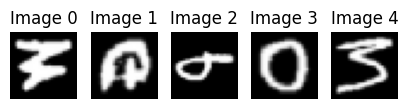

Length of labels_bytes: 124808
Magic Number (Labels) Bytes: b'\x00\x00\x08\x01'
Number of Labels Bytes: b'\x00\x01\xe7\x80'
Magic Number (Labels): 2049, Num Labels: 124800
Shape of labels: (124800,)
Label data type: uint8
Data loaded successfully!
Train images shape: (124800, 28, 28)
Train labels shape: (124800,)


In [6]:
import gzip
import numpy as np
import os
import matplotlib.pyplot as plt

def load_data(images_path, labels_path):
    print(f"load_data called with: images_path='{images_path}', labels_path='{labels_path}'")
    images = None
    labels = None
    try:
        if not os.path.exists(images_path):
            print(f"Error: Images file not found at '{images_path}'")
            return np.array([]), np.array([])
        if not os.path.exists(labels_path):
            print(f"Error: Labels file not found at '{labels_path}'")
            return np.array([]), np.array([])

        with gzip.open(images_path, 'rb') as images_file:
            images_bytes = images_file.read()
            print(f"Length of images_bytes: {len(images_bytes)}")
            magic_number_images_bytes = images_bytes[:4]
            print(f"Magic Number (Images) Bytes: {magic_number_images_bytes}")
            magic_number_images = int.from_bytes(magic_number_images_bytes, 'big')
            num_images_bytes = images_bytes[4:8]
            print(f"Number of Images Bytes: {num_images_bytes}")
            num_images = int.from_bytes(num_images_bytes, 'big')
            rows_bytes = images_bytes[8:12]
            print(f"Rows Bytes: {rows_bytes}")
            rows = int.from_bytes(rows_bytes, 'big')
            cols_bytes = images_bytes[12:16]
            print(f"Cols Bytes: {cols_bytes}")
            cols = int.from_bytes(cols_bytes, 'big')
            print(f"Magic Number (Images): {magic_number_images}, Num Images: {num_images}, Rows: {rows}, Cols: {cols}")
            images = np.frombuffer(images_bytes, np.uint8, offset=16).reshape(-1, rows, cols)
            print(f"Shape of images after reshape: {images.shape}")
            print(f"Max image value: {images.max()}, Min image value: {images.min()}")
            print(f"Image data type: {images.dtype}")

            # Visualize a few images right after loading
            plt.figure(figsize=(5, 5))
            for i in range(min(5, images.shape[0])):
                plt.subplot(1, 5, i + 1)
                plt.imshow(images[i], cmap='gray')
                plt.title(f"Image {i}")
                plt.axis('off')
            plt.show()

        with gzip.open(labels_path, 'rb') as labels_file:
            labels_bytes = labels_file.read()
            print(f"Length of labels_bytes: {len(labels_bytes)}")
            magic_number_labels_bytes = labels_bytes[:4]
            print(f"Magic Number (Labels) Bytes: {magic_number_labels_bytes}")
            magic_number_labels = int.from_bytes(magic_number_labels_bytes, 'big')
            num_labels_bytes = labels_bytes[4:8]
            print(f"Number of Labels Bytes: {num_labels_bytes}")
            num_labels = int.from_bytes(num_labels_bytes, 'big')
            print(f"Magic Number (Labels): {magic_number_labels}, Num Labels: {num_labels}")
            labels = np.frombuffer(labels_bytes, np.uint8, offset=8)
            print(f"Shape of labels: {labels.shape}")
            print(f"Label data type: {labels.dtype}")

    except FileNotFoundError as e:
        print(f"FileNotFoundError: {e}")
        return np.array([]), np.array([])
    except gzip.BadGzipFile as e:
        print(f"BadGzipFile: {e}")
        return np.array([]), np.array([])
    except Exception as e:
        print(f"General Exception: {type(e).__name__}, Message: {e}")
        return np.array([]), np.array([])
    return images, labels

images_path = "MLData/emnist-letters-train-images-idx3-ubyte.gz"
labels_path = "MLData/emnist-letters-train-labels-idx1-ubyte.gz"

train_images, train_labels = load_data(images_path, labels_path)

if train_images.size > 0:
    print("Data loaded successfully!")
    print(f"Train images shape: {train_images.shape}")
    print(f"Train labels shape: {train_labels.shape}")
else:
    print("Error: Data loading failed.")

Current working directory: /content/gdrive/My Drive/Colab Notebooks/MSDS680/last
Contents of MLData/: ['mean_std.pkl', 'emnist-letters-train-labels-idx1-ubyte.gz', 'emnist-letters-train-images-idx3-ubyte.gz', 'emnist-letters-test-labels-idx1-ubyte.gz', 'emnist-letters-test-images-idx3-ubyte.gz']
Loading images from: MLData/emnist-letters-train-images-idx3-ubyte.gz
Loading labels from: MLData/emnist-letters-train-labels-idx1-ubyte.gz
Loading images from: MLData/emnist-letters-test-images-idx3-ubyte.gz
Loading labels from: MLData/emnist-letters-test-labels-idx1-ubyte.gz


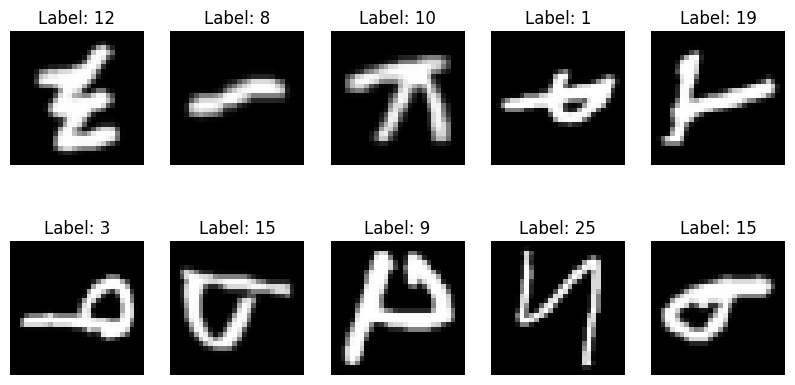

Train images shape: (99840, 28, 28)
Train labels shape: (99840, 26)
Validation images shape: (24960, 28, 28)
validation labels shape: (24960, 26)


In [7]:
import os
import gzip
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

class EMNISTDataSet:
    def __init__(self, data_dir="MLData", validation_split=0.2, reshape_to_flatten=False):
        self.data_dir = data_dir
        self.validation_split = validation_split
        self.reshape_to_flatten = reshape_to_flatten
        self.class_count = 26
        self.train_images, self.train_labels = self._load_and_preprocess(
            os.path.join(data_dir, "emnist-letters-train-images-idx3-ubyte.gz"),
            os.path.join(data_dir, "emnist-letters-train-labels-idx1-ubyte.gz"),
            is_train=True
        )
        self.test_images, self.test_labels = self._load_and_preprocess(
            os.path.join(data_dir, "emnist-letters-test-images-idx3-ubyte.gz"),
            os.path.join(data_dir, "emnist-letters-test-labels-idx1-ubyte.gz"),
            is_train=False
        )
        self._split_validation()

    def _load_and_preprocess(self, images_path, labels_path, is_train):
        print(f"Loading images from: {images_path}") #print to debug
        print(f"Loading labels from: {labels_path}") #print to debug
        try:
            with gzip.open(images_path, 'rb') as images_file:
                images = np.frombuffer(images_file.read(), np.uint8, offset=16).reshape(-1, 28, 28).astype('float32') / 255.0
                if self.reshape_to_flatten:
                    images = images.reshape(images.shape[0], -1)

            with gzip.open(labels_path, 'rb') as labels_file:
                labels = np.frombuffer(labels_file.read(), np.uint8, offset=8)

            if is_train:
                labels = labels - 1 #subtract 1 from the labels
                labels = to_categorical(labels, num_classes=self.class_count)

            return images, labels

        except FileNotFoundError as e:
            print(f"FileNotFoundError: {e}")
            return np.array([]), np.array([])
        except gzip.BadGzipFile as e:
            print(f"BadGzipFile: {e}")
            return np.array([]), np.array([])
        except Exception as e:
            print(f"General Exception: {type(e).__name__}, Message: {e}")
            return np.array([]), np.array([])

    def _split_validation(self):
        if self.train_images.size > 0:
            self.train_images, self.val_images, self.train_labels, self.val_labels = train_test_split(
                self.train_images, self.train_labels, test_size=self.validation_split, random_state=42
            )
            self.vs_sample_count = self.val_images.shape[0]
        else:
            self.val_images, self.val_labels = np.array([]), np.array([])
            self.vs_sample_count = 0

    def get_train_data(self):
        return self.train_images, self.train_labels

    def get_validation_data(self):
        return self.val_images, self.val_labels

    def get_test_data(self):
        return self.test_images, self.test_labels

    def preview_images(self, num_images=10):
        if self.train_images.size > 0 and self.train_images.shape[0] >= num_images :
            plt.figure(figsize=(10, 5))
            for i in range(num_images):
                plt.subplot(2, 5, i + 1)
                if self.reshape_to_flatten:
                    plt.imshow(self.train_images[i].reshape(28, 28), cmap='gray')
                else:
                    plt.imshow(self.train_images[i], cmap='gray')
                plt.title(f"Label: {np.argmax(self.train_labels[i])}")
                plt.axis('off')
            plt.show()
        else:
            print("No training images to preview.")

    def get_class_count(self):
        return self.class_count

    def create_data_pipeline(self, batch_size=32, crop_size=24):
        train_images, train_labels = self.get_train_data()
        val_images, val_labels = self.get_validation_data()

        # Calculate mean and std for training data
        train_mean = np.mean(train_images, axis=(0, 1, 2))
        train_std = np.std(train_images, axis=(0, 1, 2))

        def augment_and_standardize(image, label):
            # Reshape image to (28, 28, 1)
            image = tf.expand_dims(image, axis=-1)
            # Random crop
            image = tf.image.random_crop(image, [crop_size, crop_size, 1])
            # Standardization
            image = (tf.cast(image, tf.float32) - train_mean) / train_std
            return image, label

        def augment_and_standardize_validation(image, label):
            # Reshape image to (28, 28, 1)
            image = tf.expand_dims(image, axis=-1)
            # Random crop
            image = tf.image.random_crop(image, [crop_size, crop_size, 1])
            # Standardization
            image = (tf.cast(image, tf.float32) - train_mean) / train_std
            return image, label

        # Create TensorFlow datasets
        train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels))
        val_dataset = tf.data.Dataset.from_tensor_slices((val_images, val_labels))

        # Apply augmentation and standardization
        train_dataset = train_dataset.map(augment_and_standardize)
        val_dataset = val_dataset.map(augment_and_standardize_validation) # for validation set

        # Batch and prefetch
        train_dataset = train_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
        val_dataset = val_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

        return train_dataset, val_dataset

print(f"Current working directory: {os.getcwd()}")

if os.path.exists("MLData"):
    print(f"Contents of MLData/: {os.listdir('MLData')}")
else:
    print("MLData/ directory not found.")

emnist_data = EMNISTDataSet(data_dir="MLData")

emnist_data.preview_images()
train_images, train_labels = emnist_data.get_train_data()
print(f"Train images shape: {train_images.shape}")
print(f"Train labels shape: {train_labels.shape}")
val_images, val_labels = emnist_data.get_validation_data()
print(f"Validation images shape: {val_images.shape}")
print(f"validation labels shape: {val_labels.shape}")

In [8]:
import tensorflow as tf

emnist_data = EMNISTDataSet(data_dir="MLData")
train_dataset, val_dataset = emnist_data.create_data_pipeline()

# Build your neural network model
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(24, 24, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(26, activation='softmax')  # 26 classes for EMNIST letters
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(train_dataset, epochs=10, validation_data=val_dataset)

Loading images from: MLData/emnist-letters-train-images-idx3-ubyte.gz
Loading labels from: MLData/emnist-letters-train-labels-idx1-ubyte.gz
Loading images from: MLData/emnist-letters-test-images-idx3-ubyte.gz
Loading labels from: MLData/emnist-letters-test-labels-idx1-ubyte.gz
Epoch 1/10
3120/3120 [==============================] - 56s 18ms/step - loss: 0.7187 - accuracy: 0.7775 - val_loss: 0.4617 - val_accuracy: 0.8526
Epoch 2/10
3120/3120 [==============================] - 54s 17ms/step - loss: 0.4017 - accuracy: 0.8719 - val_loss: 0.3620 - val_accuracy: 0.8821
Epoch 3/10
3120/3120 [==============================] - 53s 17ms/step - loss: 0.3411 - accuracy: 0.8893 - val_loss: 0.3233 - val_accuracy: 0.8951
Epoch 4/10
3120/3120 [==============================] - 53s 17ms/step - loss: 0.3082 - accuracy: 0.8994 - val_loss: 0.3029 - val_accuracy: 0.8999
Epoch 5/10
3120/3120 [==============================] - 53s 17ms/step - loss: 0.2861 - accuracy: 0.9056 - val_loss: 0.2808 - val_accuracy:

780/780 [==============================] - 4s 5ms/step - loss: 0.2645 - accuracy: 0.9157
Validation Loss: 0.2645, Validation Accuracy: 0.9157
780/780 [==============================] - 5s 7ms/step


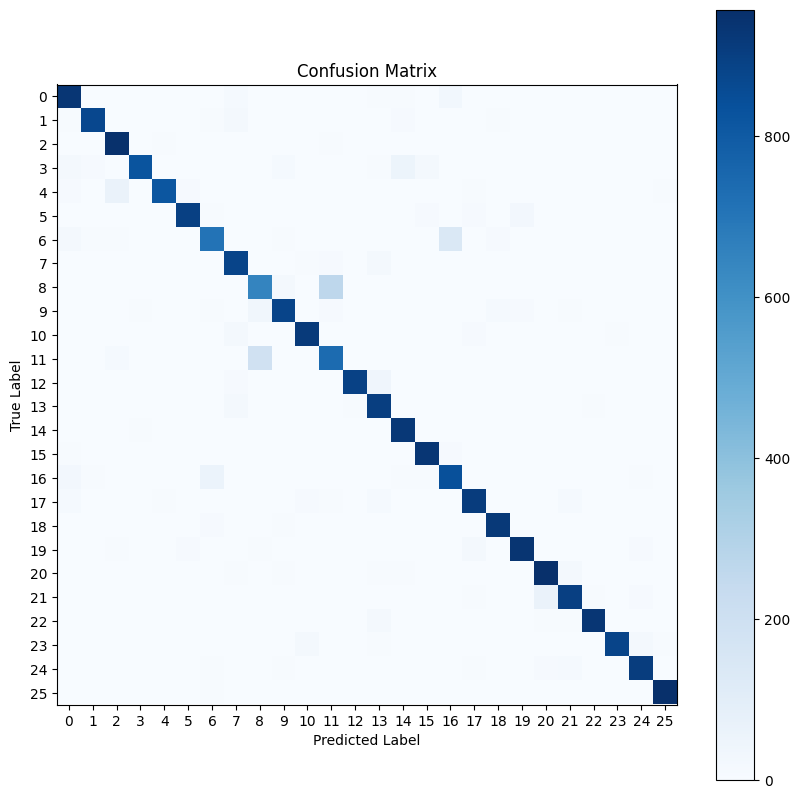

              precision    recall  f1-score   support

           0       0.89      0.93      0.91      1008
           1       0.96      0.94      0.95       927
           2       0.90      0.97      0.94       977
           3       0.97      0.87      0.92       947
           4       0.97      0.89      0.93       919
           5       0.97      0.92      0.95       970
           6       0.86      0.78      0.82       908
           7       0.90      0.94      0.92       933
           8       0.73      0.69      0.71       938
           9       0.93      0.90      0.92       975
          10       0.96      0.95      0.95       972
          11       0.70      0.77      0.74       958
          12       0.98      0.95      0.96       941
          13       0.88      0.96      0.92       941
          14       0.91      0.98      0.94       939
          15       0.95      0.96      0.95       969
          16       0.81      0.87      0.84       961
          17       0.93    

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf

# Evaluate the model
loss, accuracy = model.evaluate(val_dataset)
print(f"Validation Loss: {loss:.4f}, Validation Accuracy: {accuracy:.4f}")

# Get predictions
y_true = np.concatenate([y.numpy().argmax(axis=-1) for _, y in val_dataset])
y_pred = model.predict(val_dataset).argmax(axis=-1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 10))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
plt.xticks(np.arange(26))
plt.yticks(np.arange(26))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Classification Report
print(classification_report(y_true, y_pred))